# Prática de proteômica: PA × MB

**Google Colab com R — Minicurso EPB 2026**

Fluxo da prática:

1. Diagnóstico de valores ausentes;
2. Filtragem por presença;
3. Imputação com `msImpute`;
4. Avaliação pós-imputação e PCA;
5. Proteínas diferencialmente expressas com `limma`;
6. Enriquecimento ORA com Hallmarks;
7. Clustering exploratório opcional;
8. Compactação dos resultados.

### Antes de executar

1. Abra o notebook no Colab usando um **runtime R**.
2. No painel **Files/Arquivos**, envie `251218_1019_ProteinGroup_dia_PA_MB.txt`.
3. Execute as células em ordem.

Os arquivos do Colab são temporários. Baixe o `.zip` gerado ao final.

## 1. Verificar o runtime

In [ ]:
cat(R.version.string, "\n")
cat("Diretório atual:", getwd(), "\n")
cat("Arquivos em /content:\n")
print(list.files("/content"))

R version 4.6.1 (2026-06-24) 
Diretório atual: /content 
Arquivos em /content:
[1] "sample_data"


## 2. Instalar pacotes

A instalação é necessária a cada nova sessão do Colab. Pode levar alguns minutos.

`limma`, `msImpute`, `clusterProfiler` e `ConsensusClusterPlus` são instalados pelo Bioconductor.

In [ ]:
options(repos = c(CRAN = "https://cloud.r-project.org"), Ncpus = 2)

cran_packages <- c(
  "readr", "dplyr", "stringr", "ggplot2", "pheatmap",
  "tibble", "tidyr", "msigdbr", "BiocManager"
)

cran_missing <- cran_packages[
  !vapply(cran_packages, requireNamespace, logical(1), quietly = TRUE)
]
if (length(cran_missing)) install.packages(cran_missing)

bioc_packages <- c(
  "msImpute", "limma", "clusterProfiler", "ConsensusClusterPlus"
)

bioc_missing <- bioc_packages[
  !vapply(bioc_packages, requireNamespace, logical(1), quietly = TRUE)
]
if (length(bioc_missing)) {
  BiocManager::install(bioc_missing, ask = FALSE, update = FALSE)
}

cat("Pacotes instalados.\n")

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘assertthat’, ‘babelgene’


'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement repositories:
    CRAN: https://cloud.r-project.org

Bioconductor version 3.23 (BiocManager 1.30.27), R 4.6.1 (2026-06-24)

Installing package(s) 'BiocVersion', 'msImpute', 'limma', 'clusterProfiler',
  'ConsensusClusterPlus'

also installing the dependencies ‘fontBitstreamVera’, ‘fontLiberation’, ‘formatR’, ‘fontquiver’, ‘XVector’, ‘lambda.r’, ‘futile.options’, ‘gridGraphics’, ‘gdtools’, ‘lazyeval’, ‘tweenr’, ‘polyclip’, ‘GenomicRanges’, ‘SparseArray’, ‘assorthead’, ‘Seqinfo’, ‘futile.logger’, ‘snow’, ‘locfit’, ‘abind’, ‘ScaledMatrix’, ‘irlba’, ‘rsvd’, ‘BiocNeighbors’, ‘sitmo’, ‘Biostrings’, ‘ggplotify’, ‘patchwork’, ‘ape’, ‘ggiraph’, ‘tidytree’, ‘treeio’, ‘ggforce’, ‘RcppTOML’, ‘here’, ‘png’, ‘SingleC

Pacotes instalados.


## 3. Carregar pacotes e configurar a prática

In [ ]:
suppressPackageStartupMessages({
  library(readr)
  library(dplyr)
  library(stringr)
  library(ggplot2)
  library(pheatmap)
  library(tibble)
  library(tidyr)
  library(msImpute)
  library(limma)
  library(clusterProfiler)
  library(msigdbr)
  library(ConsensusClusterPlus)
})

# TRUE reduz o clustering de 1000 para 100 repetições.
fast_mode <- TRUE
run_clustering <- TRUE

input_file <- "/content/251218_1019_ProteinGroup_dia_PA_MB.txt"
output_dir <- "/content/resultados_PA_MB"
dir.create(output_dir, recursive = TRUE, showWarnings = FALSE)

if (!file.exists(input_file)) {
  stop(
    "Matriz não encontrada. Envie 251218_1019_ProteinGroup_dia_PA_MB.txt ",
    "pelo painel Files/Arquivos do Colab."
  )
}

cat("Entrada:", input_file, "\n")
cat("Resultados:", output_dir, "\n")

Entrada: /content/251218_1019_ProteinGroup_dia_PA_MB.txt 
Resultados: /content/resultados_PA_MB 


## 4. Carregar e organizar a matriz

In [ ]:
raw_data <- read_tsv(
  input_file,
  na = c("NA", "", "NaN"),
  show_col_types = FALSE
)

pa_cols <- paste0("PA0", 1:7)
mb_cols <- paste0("MB0", 1:7)
sample_cols <- c(pa_cols, mb_cols)
required_cols <- c("Protein.Group", "Protein.Names", "Genes", sample_cols)

missing_cols <- setdiff(required_cols, colnames(raw_data))
if (length(missing_cols)) {
  stop("Colunas ausentes: ", paste(missing_cols, collapse = ", "))
}

raw_data <- raw_data %>%
  select(all_of(required_cols)) %>%
  filter(!is.na(Genes), Genes != "") %>%
  mutate(Genes = stringr::word(Genes, 1, sep = ";")) %>%
  distinct(Genes, .keep_all = TRUE)

intensity_matrix <- raw_data %>%
  select(all_of(sample_cols)) %>%
  as.matrix()

rownames(intensity_matrix) <- raw_data$Genes
mode(intensity_matrix) <- "numeric"

group_vector <- factor(
  c(rep("PA", length(pa_cols)), rep("MB", length(mb_cols))),
  levels = c("PA", "MB")
)
names(group_vector) <- sample_cols

cat("Proteínas:", nrow(intensity_matrix), "\n")
cat("Amostras:", ncol(intensity_matrix), "\n")
cat("NAs totais:", sum(is.na(intensity_matrix)), "\n")

Proteínas: 8429 
Amostras: 14 
NAs totais: 53405 


## 5. Diagnóstico de valores ausentes

# A tibble: 14 × 5
   sample group missing total pct_missing
   <chr>  <chr>   <dbl> <int>       <dbl>
 1 PA01   PA       4472  8429        53.1
 2 PA02   PA       4018  8429        47.7
 3 PA03   PA       4017  8429        47.7
 4 PA04   PA       3803  8429        45.1
 5 PA05   PA       4114  8429        48.8
 6 PA06   PA       3815  8429        45.3
 7 PA07   PA       4013  8429        47.6
 8 MB01   MB       3281  8429        38.9
 9 MB02   MB       3337  8429        39.6
10 MB03   MB       3905  8429        46.3
11 MB04   MB       3675  8429        43.6
12 MB05   MB       3860  8429        45.8
13 MB06   MB       3392  8429        40.2
14 MB07   MB       3703  8429        43.9
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   0.00    0.00   42.86   45.26   85.71  100.00 


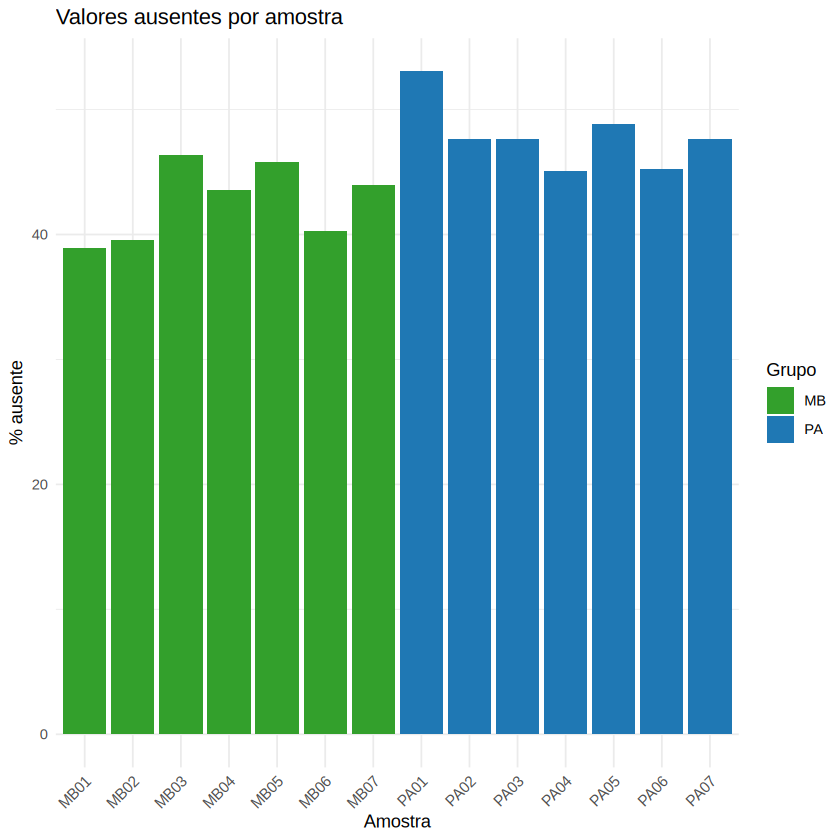

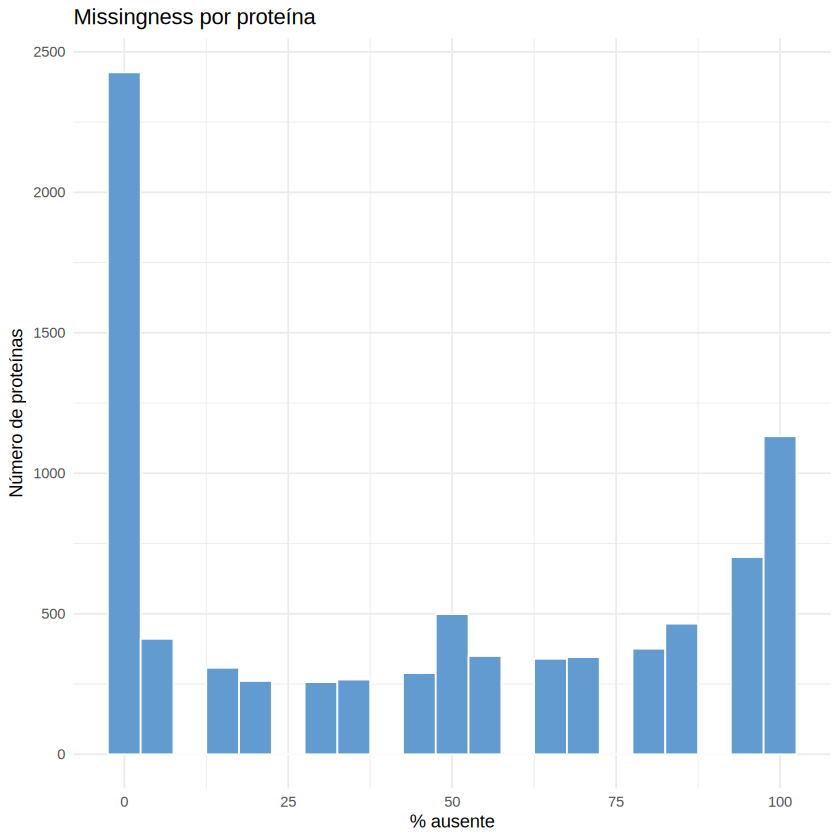

In [ ]:
na_summary_sample <- tibble(
  sample = colnames(intensity_matrix),
  group = as.character(group_vector),
  missing = colSums(is.na(intensity_matrix)),
  total = nrow(intensity_matrix),
  pct_missing = 100 * missing / total
)

na_summary_protein <- tibble(
  gene = rownames(intensity_matrix),
  missing = rowSums(is.na(intensity_matrix)),
  total = ncol(intensity_matrix),
  pct_missing = 100 * missing / total
)

write_csv(
  na_summary_sample,
  file.path(output_dir, "diagnostico_NAs_por_amostra_PA_MB.csv")
)
write_csv(
  na_summary_protein,
  file.path(output_dir, "diagnostico_NAs_por_proteina_PA_MB.csv")
)

print(na_summary_sample)
print(summary(na_summary_protein$pct_missing))

p_na_sample <- ggplot(
  na_summary_sample,
  aes(x = sample, y = pct_missing, fill = group)
) +
  geom_col() +
  scale_fill_manual(values = c(PA = "#1f78b4", MB = "#33a02c")) +
  labs(
    title = "Valores ausentes por amostra",
    x = "Amostra", y = "% ausente", fill = "Grupo"
  ) +
  theme_minimal() +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))

print(p_na_sample)
ggsave(
  file.path(output_dir, "NA_por_amostra_PA_MB.png"),
  p_na_sample, width = 8, height = 5, dpi = 200
)

p_na_protein <- ggplot(na_summary_protein, aes(x = pct_missing)) +
  geom_histogram(binwidth = 5, fill = "#629BD0", color = "white") +
  labs(
    title = "Missingness por proteína",
    x = "% ausente", y = "Número de proteínas"
  ) +
  theme_minimal()

print(p_na_protein)
ggsave(
  file.path(output_dir, "NA_por_proteina_PA_MB.png"),
  p_na_protein, width = 8, height = 5, dpi = 200
)

### Perguntas

- Qual amostra possui maior percentual de valores ausentes?
- PA e MB apresentam missingness semelhante?
- A ausência parece aleatória ou associada à baixa abundância?

## 6. Filtrar proteínas

In [ ]:
# Manter proteínas observadas em pelo menos 50% de PA ou 50% de MB.
keep_pa <- rowMeans(!is.na(intensity_matrix[, pa_cols, drop = FALSE])) >= 0.50
keep_mb <- rowMeans(!is.na(intensity_matrix[, mb_cols, drop = FALSE])) >= 0.50
keep_proteins <- keep_pa | keep_mb

filtered_matrix <- intensity_matrix[keep_proteins, , drop = FALSE]
filtered_matrix <- filtered_matrix[
  rowSums(!is.na(filtered_matrix)) >= 4,
  , drop = FALSE
]

cat("Antes da filtragem:", nrow(intensity_matrix), "proteínas\n")
cat("Após a filtragem:", nrow(filtered_matrix), "proteínas\n")
cat("NAs após filtragem:", sum(is.na(filtered_matrix)), "\n")

write_csv(
  as.data.frame(filtered_matrix) %>% rownames_to_column("Gene"),
  file.path(output_dir, "PA_MB_intensidades_filtradas.csv")
)

Antes da filtragem: 8429 proteínas
Após a filtragem: 5540 proteínas
NAs após filtragem: 16701 


## 7. Imputar com `msImpute`

In [ ]:
set.seed(123)

missing_features <- selectFeatures(
  filtered_matrix,
  group = group_vector
)

cat(
  "Proteínas classificadas como MNAR:",
  sum(missing_features$msImpute_feature == TRUE), "\n"
)
cat(
  "Proteínas classificadas como MAR:",
  sum(missing_features$msImpute_feature == FALSE), "\n"
)

imputed_matrix <- msImpute(
  filtered_matrix,
  method = "v2",
  group = group_vector
)

stopifnot(sum(is.na(imputed_matrix)) == 0)
cat("NAs após imputação:", sum(is.na(imputed_matrix)), "\n")

write_csv(
  as.data.frame(imputed_matrix) %>% rownames_to_column("Gene"),
  file.path(output_dir, "PA_MB_intensidades_imputadas.csv")
)

Proteínas classificadas como MNAR: 900 
Proteínas classificadas como MAR: 4640 


Running msImpute version 2

Estimate distribution under MAR assumption

rank is 7

computing lambda0 ...

lambda0 is 29.4361761682867

fit the low-rank model ...

model fitted. 
Imputting missing entries ...

Imputation completed



NAs após imputação: 0 


## 8. Avaliar a imputação

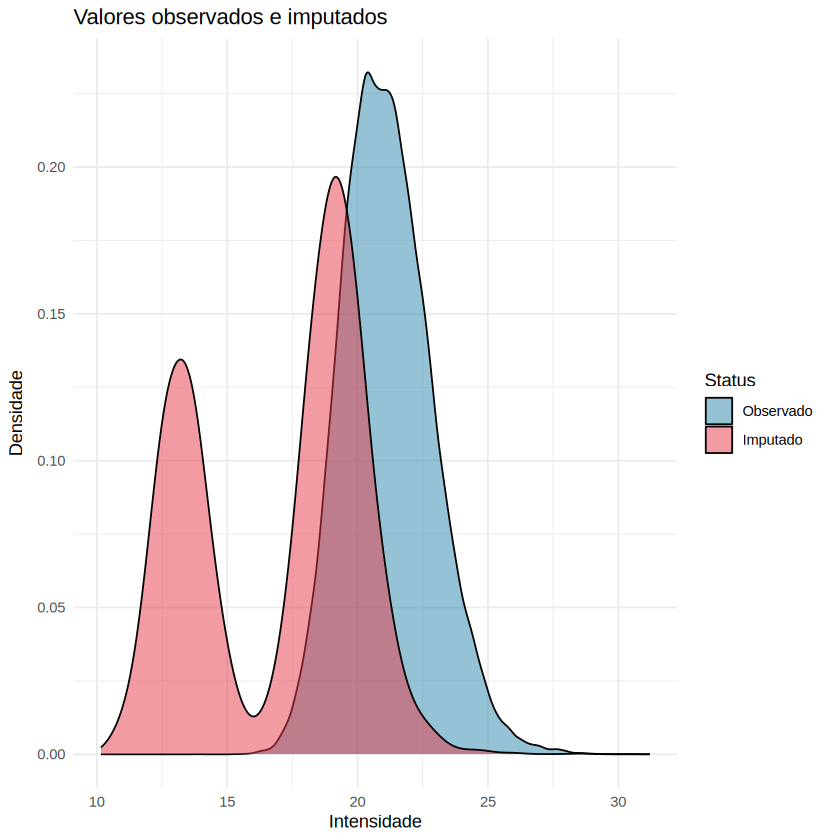

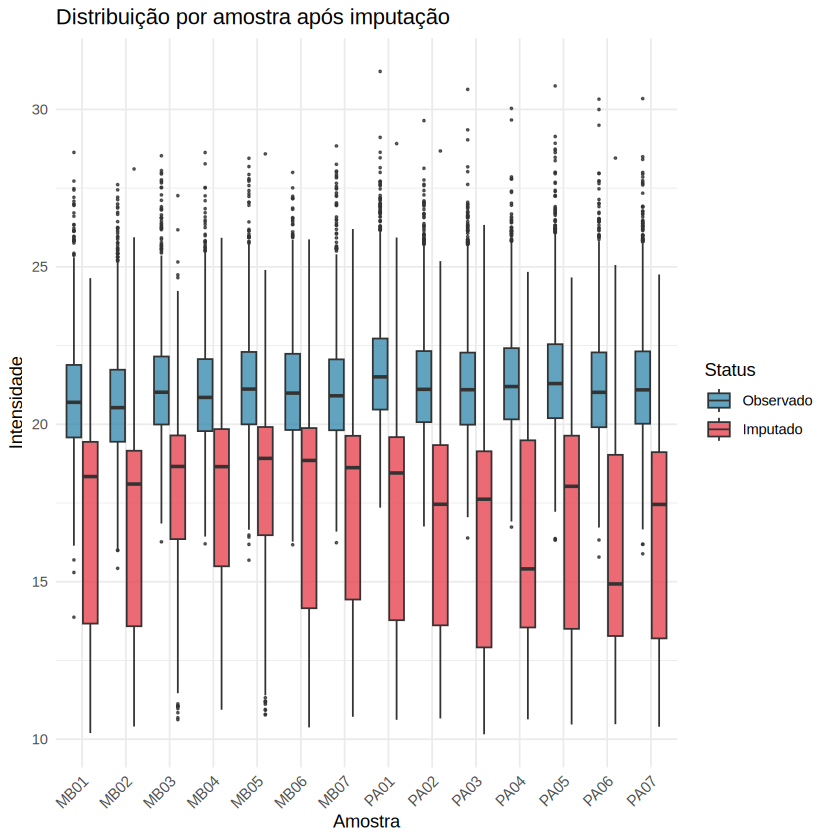

In [ ]:
na_mask <- is.na(filtered_matrix)

plot_df <- tibble(
  Gene = rep(rownames(imputed_matrix), times = ncol(imputed_matrix)),
  Sample = rep(colnames(imputed_matrix), each = nrow(imputed_matrix)),
  Value = as.vector(imputed_matrix),
  Imputed = as.vector(na_mask)
)

p_density <- ggplot(plot_df, aes(x = Value, fill = Imputed)) +
  geom_density(alpha = 0.5) +
  scale_fill_manual(
    values = c("FALSE" = "#2E86AB", "TRUE" = "#E63946"),
    labels = c("Observado", "Imputado")
  ) +
  labs(
    title = "Valores observados e imputados",
    x = "Intensidade", y = "Densidade", fill = "Status"
  ) +
  theme_minimal()

print(p_density)
ggsave(
  file.path(output_dir, "PA_MB_density_observed_vs_imputed.png"),
  p_density, width = 8, height = 5, dpi = 200
)

p_box <- ggplot(plot_df, aes(x = Sample, y = Value, fill = Imputed)) +
  geom_boxplot(outlier.size = 0.4, alpha = 0.75) +
  scale_fill_manual(
    values = c("FALSE" = "#2E86AB", "TRUE" = "#E63946"),
    labels = c("Observado", "Imputado")
  ) +
  labs(
    title = "Distribuição por amostra após imputação",
    x = "Amostra", y = "Intensidade", fill = "Status"
  ) +
  theme_minimal() +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))

print(p_box)
ggsave(
  file.path(output_dir, "PA_MB_boxplot_imputed.png"),
  p_box, width = 10, height = 6, dpi = 200
)

## 9. PCA das amostras

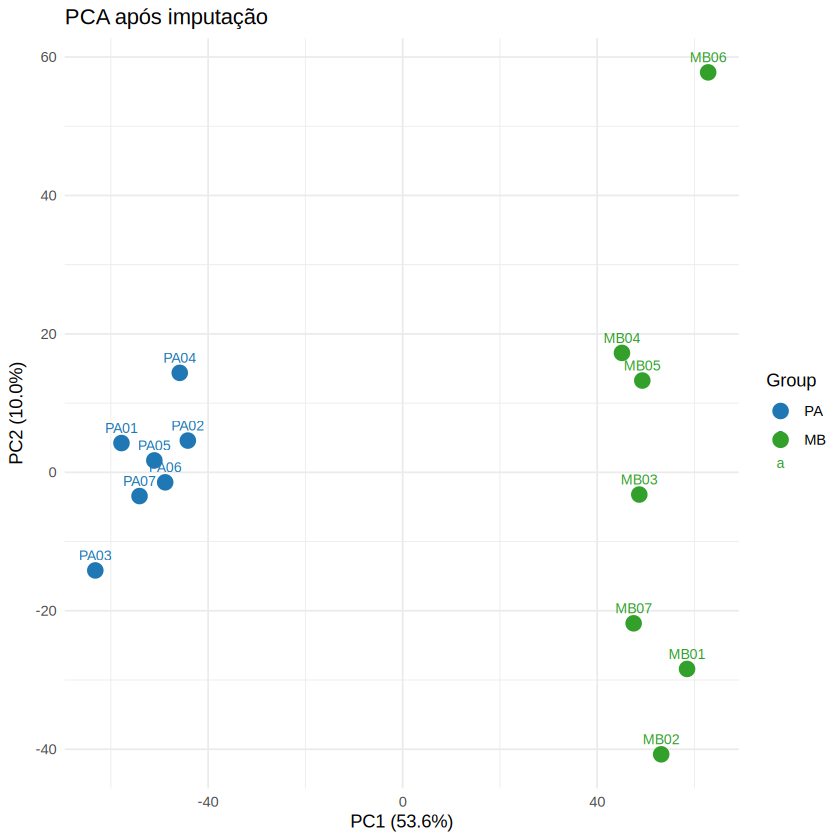

In [ ]:
scaled_matrix <- t(scale(t(imputed_matrix)))
scaled_matrix[!is.finite(scaled_matrix)] <- 0

pca <- prcomp(t(scaled_matrix), center = TRUE, scale. = FALSE)
variance <- 100 * pca$sdev^2 / sum(pca$sdev^2)

pca_df <- tibble(
  Sample = rownames(pca$x),
  PC1 = pca$x[, 1],
  PC2 = pca$x[, 2],
  Group = group_vector[rownames(pca$x)]
)

p_pca <- ggplot(pca_df, aes(PC1, PC2, color = Group, label = Sample)) +
  geom_point(size = 4) +
  geom_text(vjust = -1, size = 3) +
  scale_color_manual(values = c(PA = "#1f78b4", MB = "#33a02c")) +
  labs(
    title = "PCA após imputação",
    x = sprintf("PC1 (%.1f%%)", variance[1]),
    y = sprintf("PC2 (%.1f%%)", variance[2])
  ) +
  theme_minimal()

print(p_pca)
ggsave(
  file.path(output_dir, "PA_MB_PCA_imputado.png"),
  p_pca, width = 8, height = 6, dpi = 200
)
write_csv(pca_df, file.path(output_dir, "PA_MB_PCA_scores.csv"))

### Perguntas

- PA e MB separam-se nos primeiros componentes?
- Existe alguma amostra isolada do próprio grupo?
- A separação é compatível com a distribuição de NAs?

## 10. Proteínas diferencialmente expressas com `limma`

In [ ]:
# Contraste positivo: maior abundância em MB.
group_factor <- factor(group_vector, levels = c("MB", "PA"))
design <- model.matrix(~0 + group_factor)
colnames(design) <- levels(group_factor)

fit <- lmFit(imputed_matrix, design)
contrast_matrix <- makeContrasts(MB_vs_PA = MB - PA, levels = design)
fit2 <- contrasts.fit(fit, contrast_matrix)
fit2 <- eBayes(fit2)

results_limma <- topTable(
  fit2,
  coef = "MB_vs_PA",
  number = Inf,
  adjust.method = "BH"
) %>%
  rownames_to_column("Gene") %>%
  select(Gene, logFC, AveExpr, P.Value, adj.P.Val, t, B)

deps <- results_limma %>%
  filter(adj.P.Val < 0.01, abs(logFC) >= 1) %>%
  arrange(adj.P.Val)

deps_up <- deps %>% filter(logFC > 0)
deps_down <- deps %>% filter(logFC < 0)

write_csv(results_limma, file.path(output_dir, "MB_vs_PA_limma_results.csv"))
write_csv(deps, file.path(output_dir, "MB_vs_PA_DEPs.csv"))
write_csv(deps_up, file.path(output_dir, "MB_vs_PA_DEPs_up.csv"))
write_csv(deps_down, file.path(output_dir, "MB_vs_PA_DEPs_down.csv"))
write_csv(head(deps, 20), file.path(output_dir, "MB_vs_PA_top20_DEPs.csv"))

cat("DEPs totais:", nrow(deps), "\n")
cat("Maior abundância em MB:", nrow(deps_up), "\n")
cat("Menor abundância em MB:", nrow(deps_down), "\n")
head(deps, 20)

DEPs totais: 2718 
Maior abundância em MB: 1371 
Menor abundância em MB: 1347 


,Gene,logFC,AveExpr,P.Value,adj.P.Val,t,B
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,ASAP3,-6.925833,17.28759,1.887110e-18,1.905699e-15,-38.94731,31.32054
2,MBNL1,-6.980124,17.47713,2.151346e-18,1.905699e-15,-38.65356,31.21726
3,PTPRE,-7.188341,18.02970,2.181218e-18,1.905699e-15,-38.62277,31.20637
4,NOS1AP,-6.857399,17.01140,2.595448e-18,1.905699e-15,-38.23667,31.06869
5,LSM14B,6.924953,18.91274,2.904252e-18,1.905699e-15,37.98905,30.97931
6,MYH14,-7.110697,17.92304,3.363015e-18,1.905699e-15,-37.66835,30.86228
7,ITGB8,-7.081032,17.88100,3.698729e-18,1.905699e-15,-37.46170,30.78610
8,RNF2,6.570147,17.97726,4.122561e-18,1.905699e-15,37.22745,30.69900
9,PHKG1,-7.315772,17.99071,4.319023e-18,1.905699e-15,-37.12736,30.66154


## 11. Volcano plot

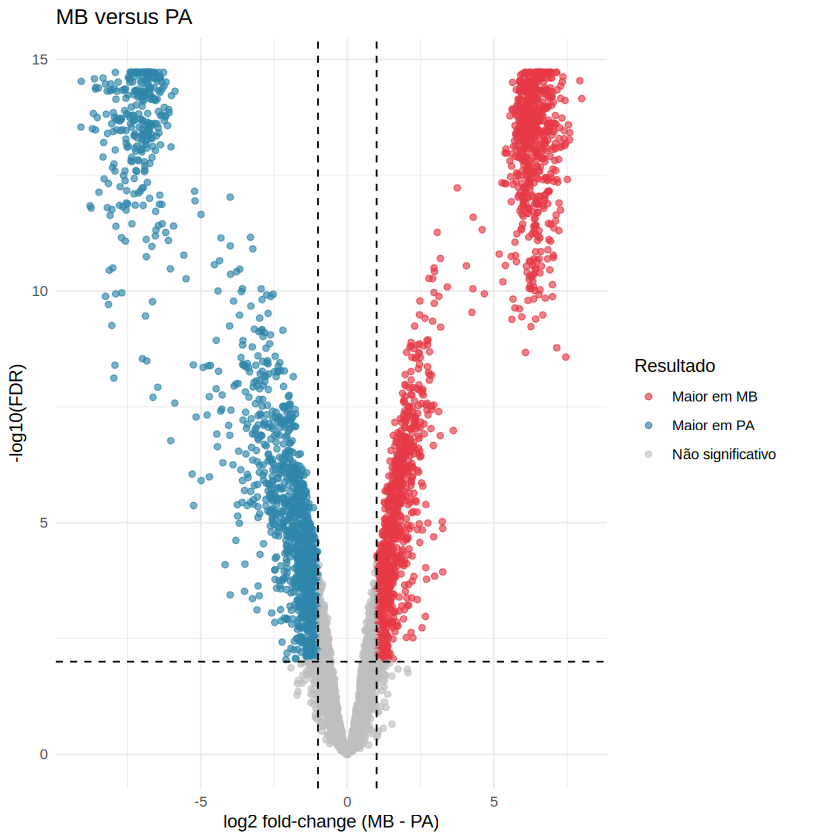

In [ ]:
volcano_df <- results_limma %>%
  mutate(
    status = case_when(
      adj.P.Val < 0.01 & logFC >= 1 ~ "Maior em MB",
      adj.P.Val < 0.01 & logFC <= -1 ~ "Maior em PA",
      TRUE ~ "Não significativo"
    ),
    minus_log10_fdr = -log10(pmax(adj.P.Val, .Machine$double.xmin))
  )

p_volcano <- ggplot(volcano_df, aes(logFC, minus_log10_fdr, color = status)) +
  geom_point(alpha = 0.65, size = 1.5) +
  geom_vline(xintercept = c(-1, 1), linetype = 2) +
  geom_hline(yintercept = -log10(0.01), linetype = 2) +
  scale_color_manual(values = c(
    "Maior em MB" = "#E63946",
    "Maior em PA" = "#2E86AB",
    "Não significativo" = "grey75"
  )) +
  labs(
    title = "MB versus PA",
    x = "log2 fold-change (MB - PA)",
    y = "-log10(FDR)", color = "Resultado"
  ) +
  theme_minimal()

print(p_volcano)
ggsave(
  file.path(output_dir, "MB_vs_PA_volcano.png"),
  p_volcano, width = 8, height = 6, dpi = 200
)

## 12. Enriquecimento ORA com Hallmarks

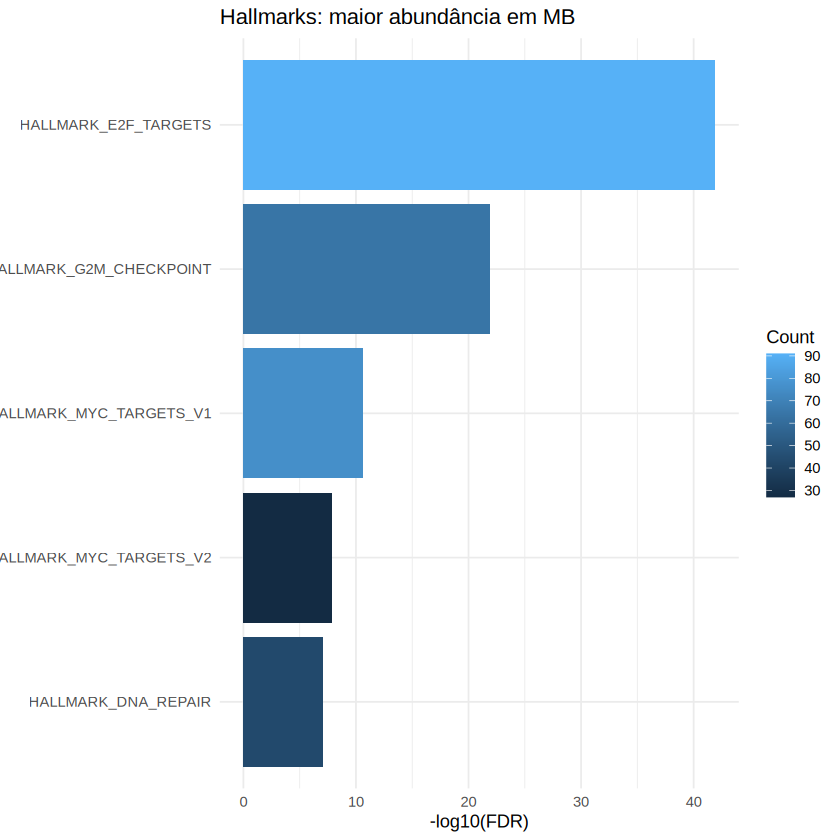

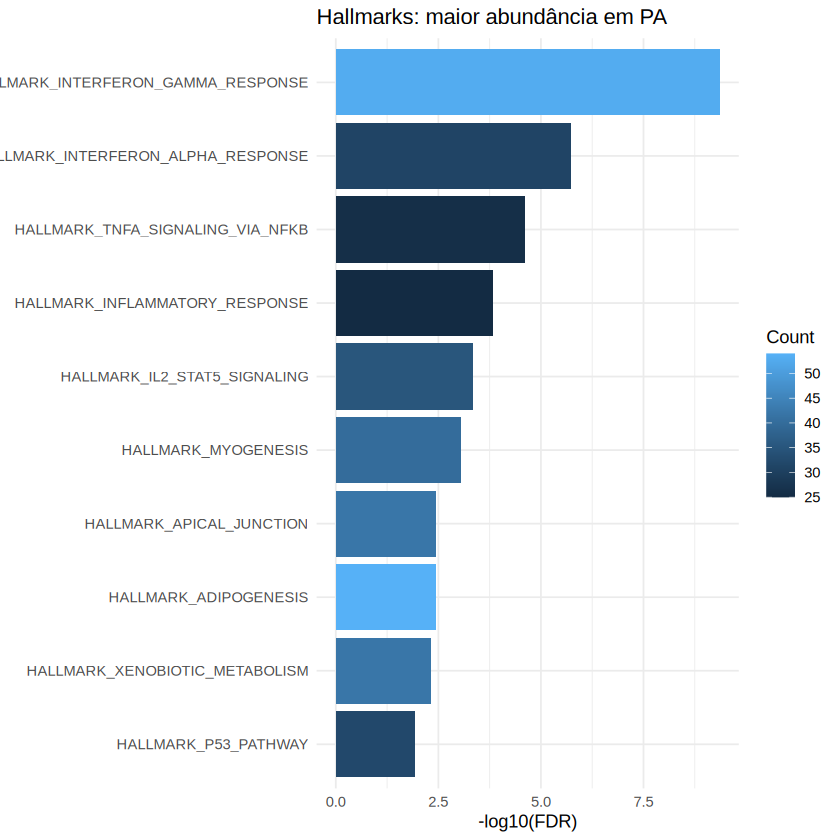

In [ ]:
hallmarks_raw <- msigdbr(species = "Homo sapiens", collection = "H")
gs_col <- intersect(
  c("gs_name", "gs_id", "gs_description", "gs_subcat"),
  colnames(hallmarks_raw)
)[1]
gene_col <- intersect(
  c("gene_symbol", "gene", "human_gene_symbol"),
  colnames(hallmarks_raw)
)[1]

if (is.na(gs_col) || is.na(gene_col)) {
  stop("Colunas de termo/gene não encontradas na versão atual de msigdbr.")
}

term2gene <- hallmarks_raw %>%
  select(term = all_of(gs_col), gene = all_of(gene_col)) %>%
  distinct()

run_ora <- function(query_genes, prefix) {
  if (!length(query_genes)) return(NULL)

  ora <- clusterProfiler::enricher(
    gene = query_genes,
    TERM2GENE = term2gene,
    universe = rownames(imputed_matrix),
    pAdjustMethod = "BH",
    pvalueCutoff = 0.05,
    qvalueCutoff = 0.20
  )

  if (is.null(ora)) return(NULL)
  result <- as.data.frame(ora)
  if (!nrow(result)) return(NULL)

  write_csv(
    result,
    file.path(output_dir, paste0("MB_vs_PA_Hallmarks_", prefix, ".csv"))
  )
  result
}

ora_up <- run_ora(deps_up$Gene, "up")
ora_down <- run_ora(deps_down$Gene, "down")

plot_ora <- function(df, title) {
  if (is.null(df) || !nrow(df)) {
    cat("Sem termos significativos para:", title, "\n")
    return(NULL)
  }

  top <- df %>%
    arrange(p.adjust) %>%
    slice_head(n = 10) %>%
    mutate(Description = factor(Description, levels = rev(Description)))

  ggplot(top, aes(Description, -log10(p.adjust), fill = Count)) +
    geom_col() +
    coord_flip() +
    labs(title = title, x = NULL, y = "-log10(FDR)") +
    theme_minimal()
}

p_ora_up <- plot_ora(ora_up, "Hallmarks: maior abundância em MB")
p_ora_down <- plot_ora(ora_down, "Hallmarks: maior abundância em PA")

if (!is.null(p_ora_up)) {
  print(p_ora_up)
  ggsave(
    file.path(output_dir, "MB_vs_PA_Hallmarks_up.png"),
    p_ora_up, width = 9, height = 6, dpi = 200
  )
}
if (!is.null(p_ora_down)) {
  print(p_ora_down)
  ggsave(
    file.path(output_dir, "MB_vs_PA_Hallmarks_down.png"),
    p_ora_down, width = 9, height = 6, dpi = 200
  )
}

### Perguntas

- Quais vias aparecem entre proteínas com maior abundância em MB?
- Quais vias aparecem entre proteínas com maior abundância em PA?
- Os genes que dirigem o enriquecimento também estão entre os maiores efeitos?
- O universo usado contém apenas genes detectados no experimento?

## 13. Resumo e compactação dos resultados

*   Item da lista
*   Item da lista



In [ ]:
summary_file <- file.path(output_dir, "RESUMO_PRATICA.txt")
summary_lines <- c(
  "PRÁTICA PROTEÔMICA PA VERSUS MB",
  sprintf("Proteínas iniciais: %d", nrow(intensity_matrix)),
  sprintf("Proteínas após filtragem: %d", nrow(filtered_matrix)),
  sprintf("NAs iniciais: %d", sum(is.na(intensity_matrix))),
  sprintf("NAs após imputação: %d", sum(is.na(imputed_matrix))),
  sprintf("DEPs: %d", nrow(deps)),
  sprintf("Maior abundância em MB: %d", nrow(deps_up)),
  sprintf("Maior abundância em PA: %d", nrow(deps_down)),
  sprintf("Modo rápido: %s", fast_mode)
)
writeLines(summary_lines, summary_file)
cat(paste(summary_lines, collapse = "\n"), "\n")

zip_file <- "/content/resultados_PA_MB.zip"
if (file.exists(zip_file)) file.remove(zip_file)

old_wd <- getwd()
setwd("/content")
system("zip -rq resultados_PA_MB.zip resultados_PA_MB")
setwd(old_wd)

cat("\nArquivo gerado:", zip_file, "\n")
cat("Baixe pelo painel Files/Arquivos do Colab.\n")

PRÁTICA PROTEÔMICA PA VERSUS MB
Proteínas iniciais: 8429
Proteínas após filtragem: 5540
NAs iniciais: 53405
NAs após imputação: 0
DEPs: 2718
Maior abundância em MB: 1371
Maior abundância em PA: 1347
Modo rápido: TRUE 

Arquivo gerado: /content/resultados_PA_MB.zip 
Baixe pelo painel Files/Arquivos do Colab.


## Checklist de interpretação

- A filtragem preservou proteínas com suporte experimental suficiente?
- A distribuição dos valores imputados é plausível?
- O PCA separa PA e MB sem ser dirigido por uma única amostra?
- Os DEPs combinam FDR e tamanho de efeito?
- Os Hallmarks são coerentes com os genes principais?
- Os resultados seriam reproduzidos em uma coorte independente?